In [1]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm
from models import bom

In [2]:
import importlib
importlib.reload(generate_utils)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [3]:
file_id = 19

weights = (0.1, -0.25)
n_neurons = 6
# states = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
states = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN']

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(filename_gcamp,
 discrete_states, eigenworms) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

In [5]:
# generate
(filename,
 modes,
 traces_reconstructed,
 traces_residual,
 traces,
 params,
 params_cca) = generate_utils.artificialize(weights, hgm,
												 filename_gcamp,
												 [f'N{i}' for i in range(n_neurons)],
												 eigenworms,
												 discrete_states[states],
												 n_dimensions=len(states))

In [6]:
neurons = [f'N{i}' for i in range(n_neurons)]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [7]:
# # reduce
#
# (modes_manifold, modes_manifold_b,
#  recos_manifold, recos_manifold_b,
#  loads_cca_man, loads_cca_man_b,
#  vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
# 																	[ds[selection_bhl] for ds in discrete_states],
# 																	zscore=(False, False),
# 																	n_cv=dims, n_pc=dims_preca)
#
# modes = modes_manifold
# traces_reconstructed = recos_manifold
# traces_residual = [trace - trace_man for trace, trace_man in zip(traces, traces_reconstructed)]

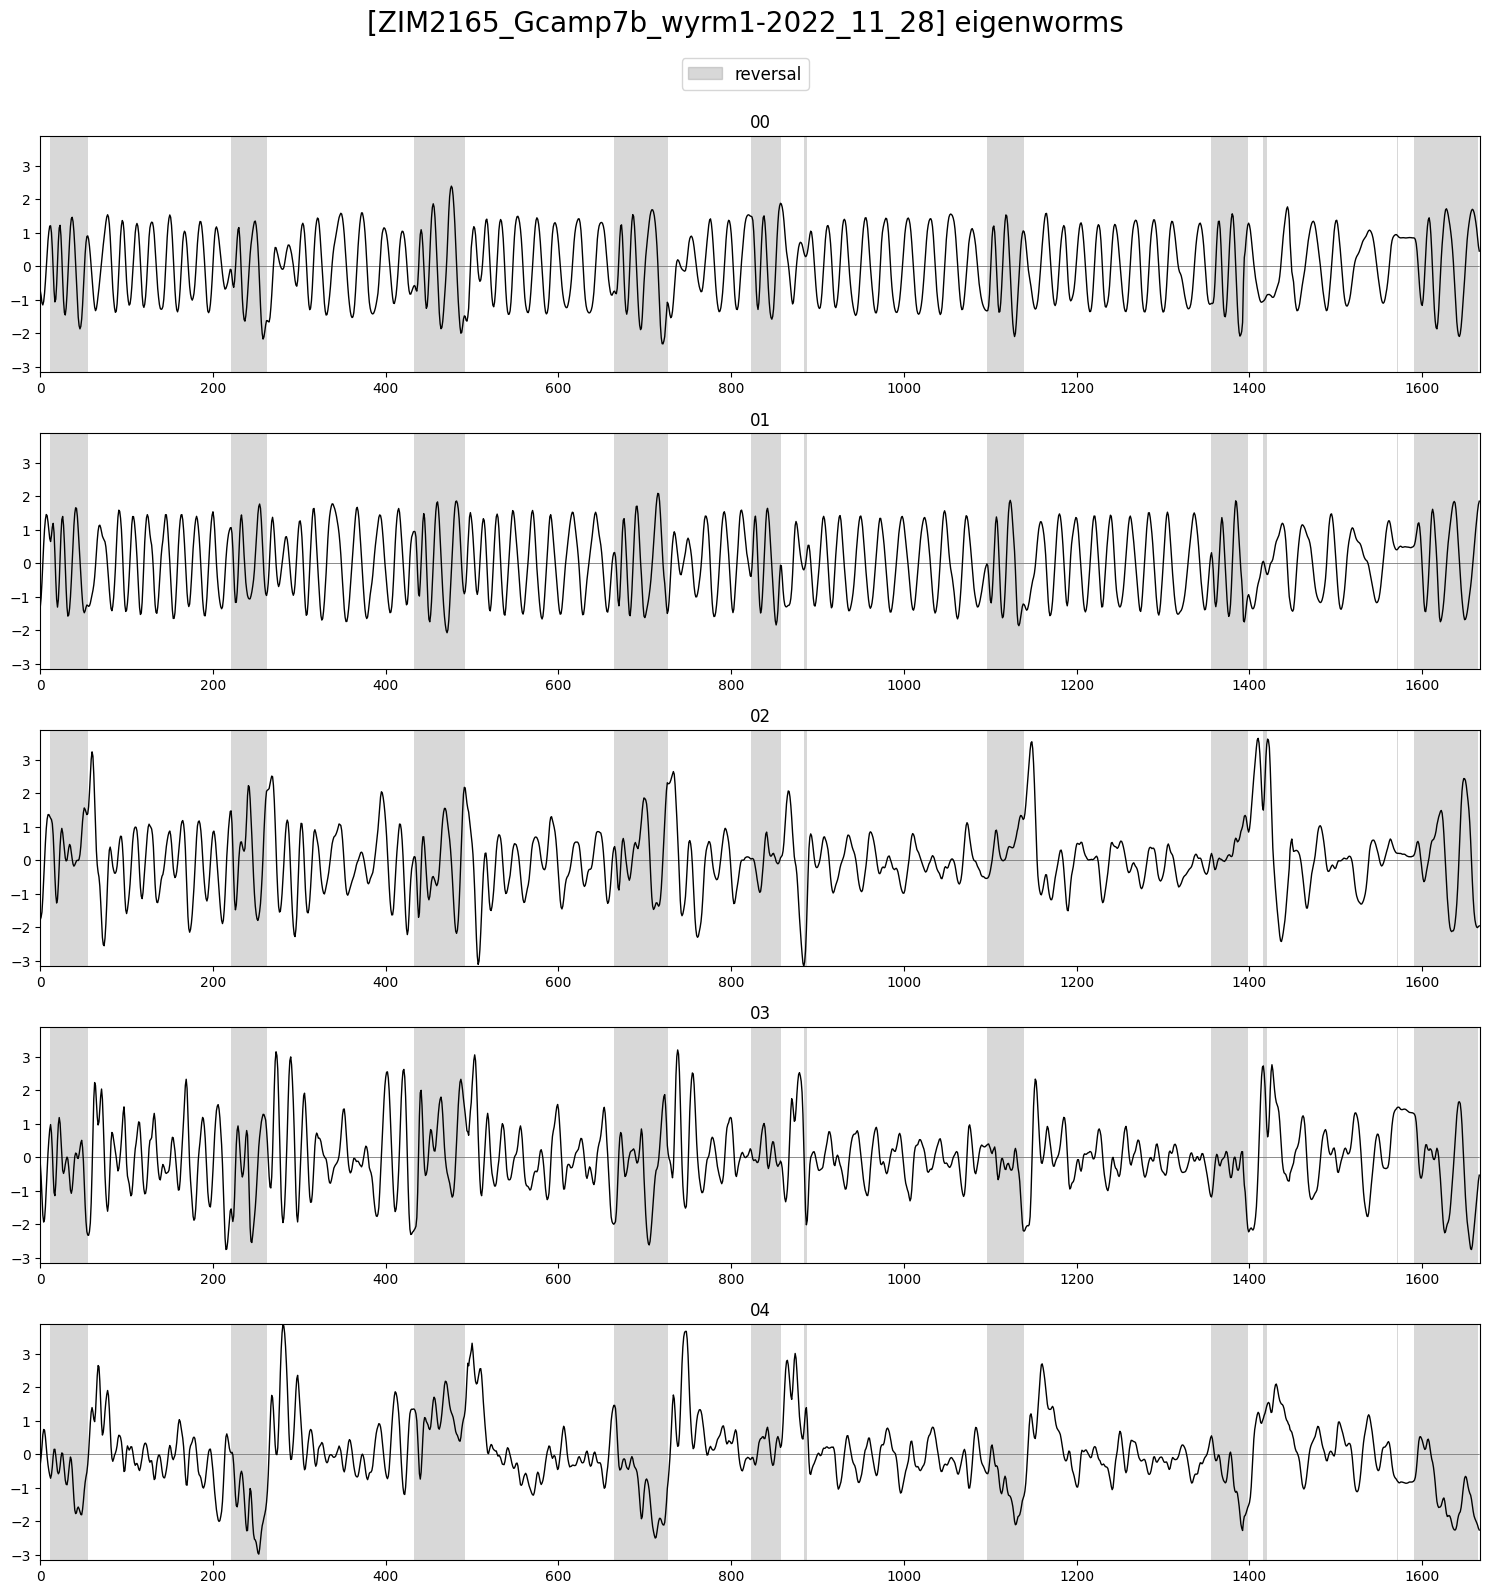

In [8]:
plot_utils.plot_traces(eigenworms,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] eigenworms', ylimits=None, plots_per_row=1)

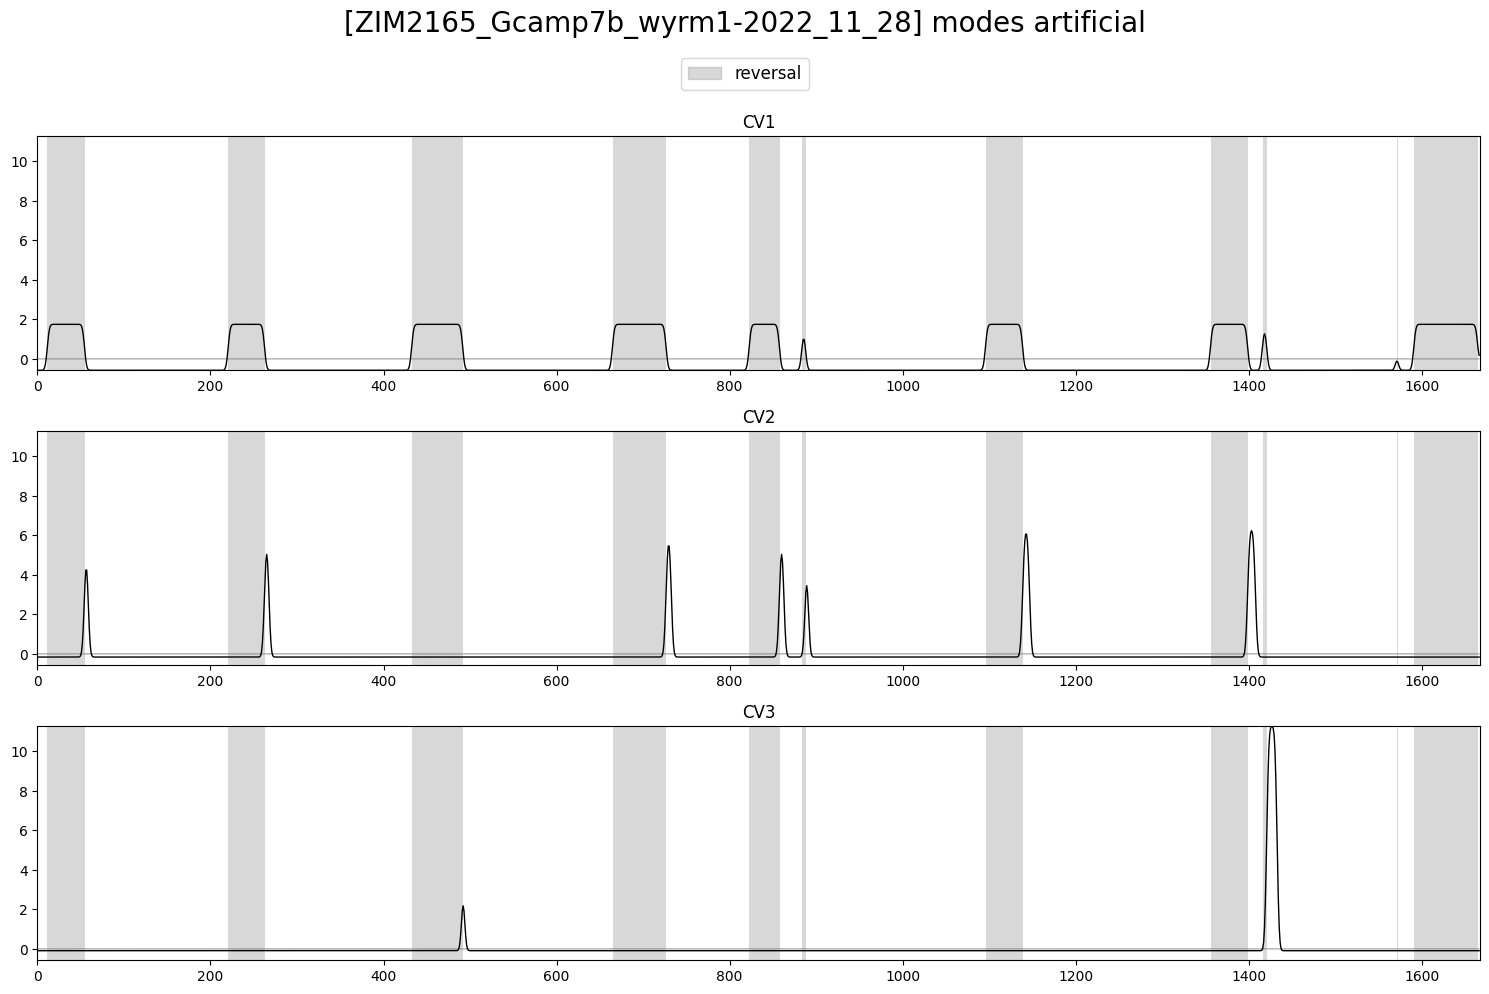

In [9]:
plot_utils.plot_traces(modes,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] modes artificial', ylimits=None, plots_per_row=1)

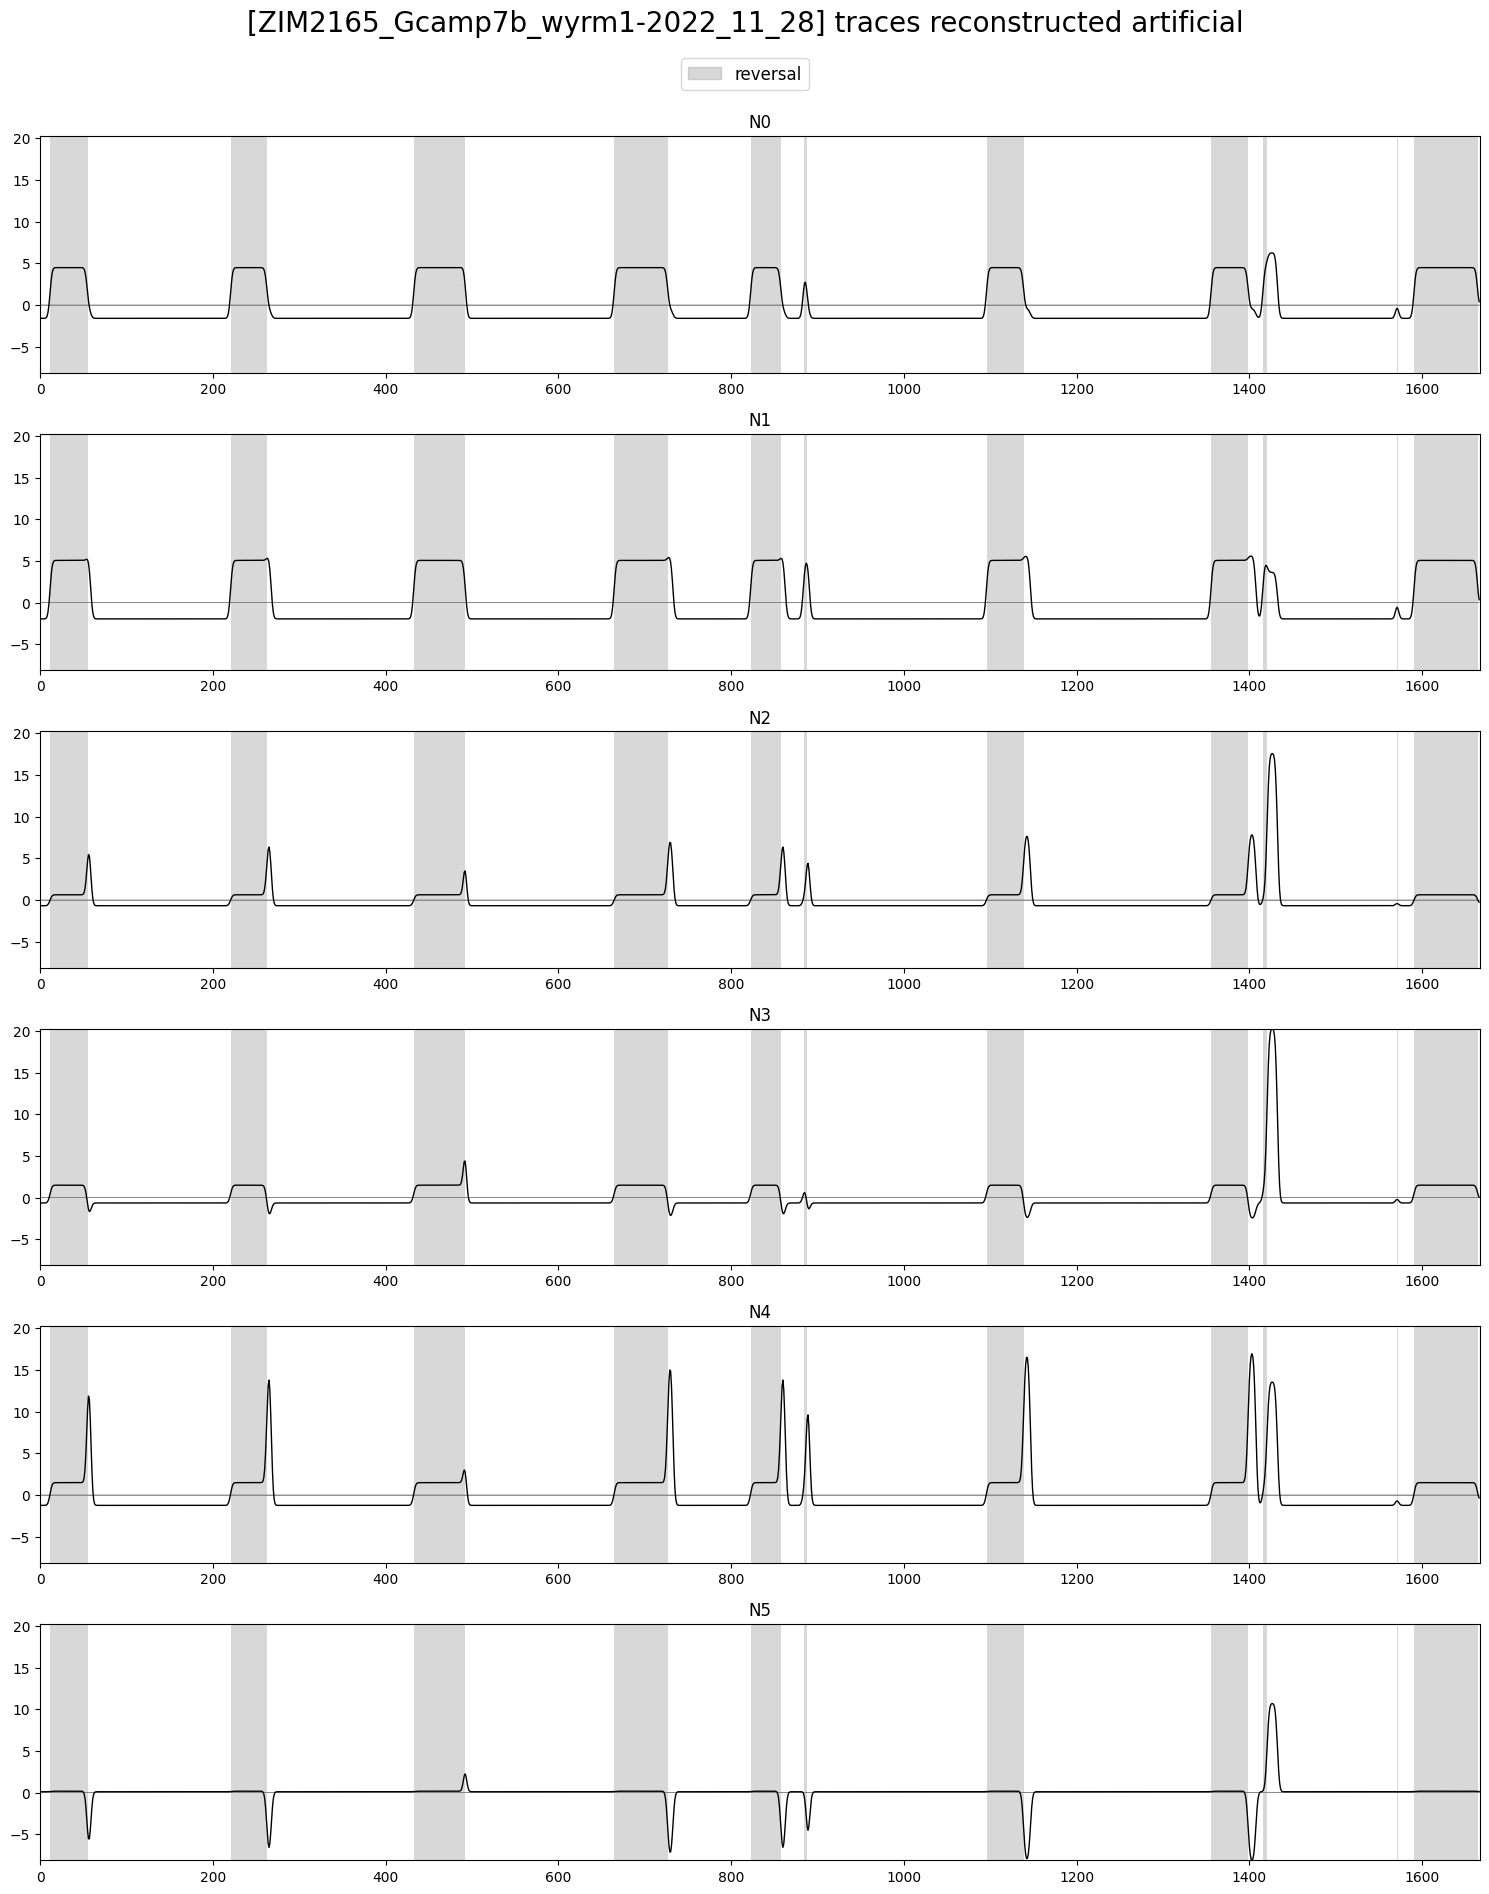

In [10]:
plot_utils.plot_traces(traces_reconstructed[neurons],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces reconstructed artificial', ylimits=None, plots_per_row=1)

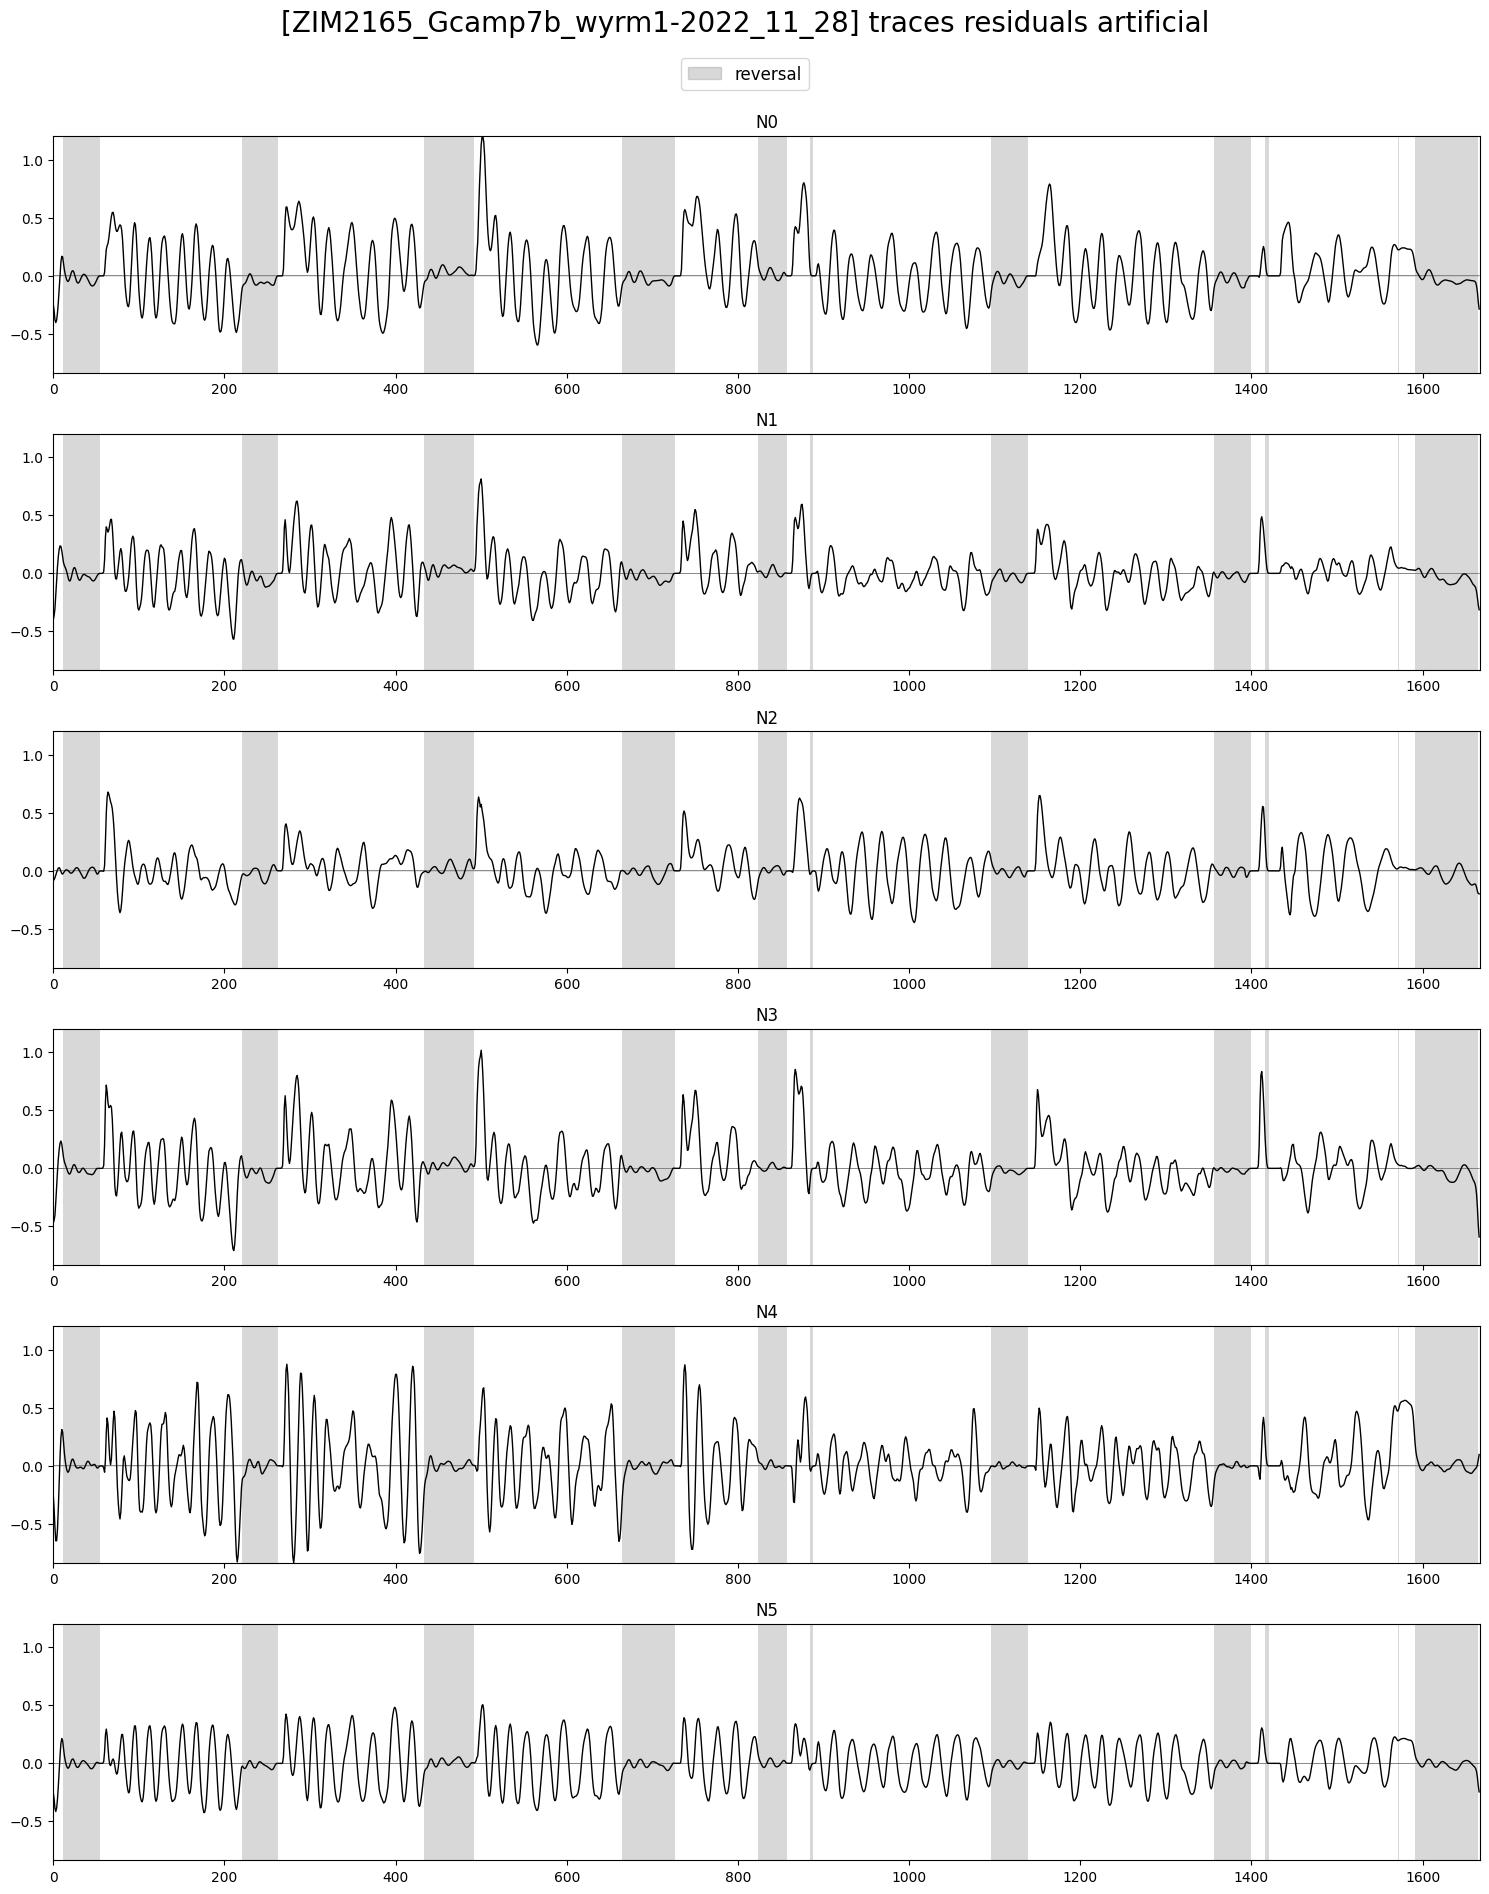

In [11]:
plot_utils.plot_traces(traces_residual[neurons],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces residuals artificial', ylimits=None, plots_per_row=1)

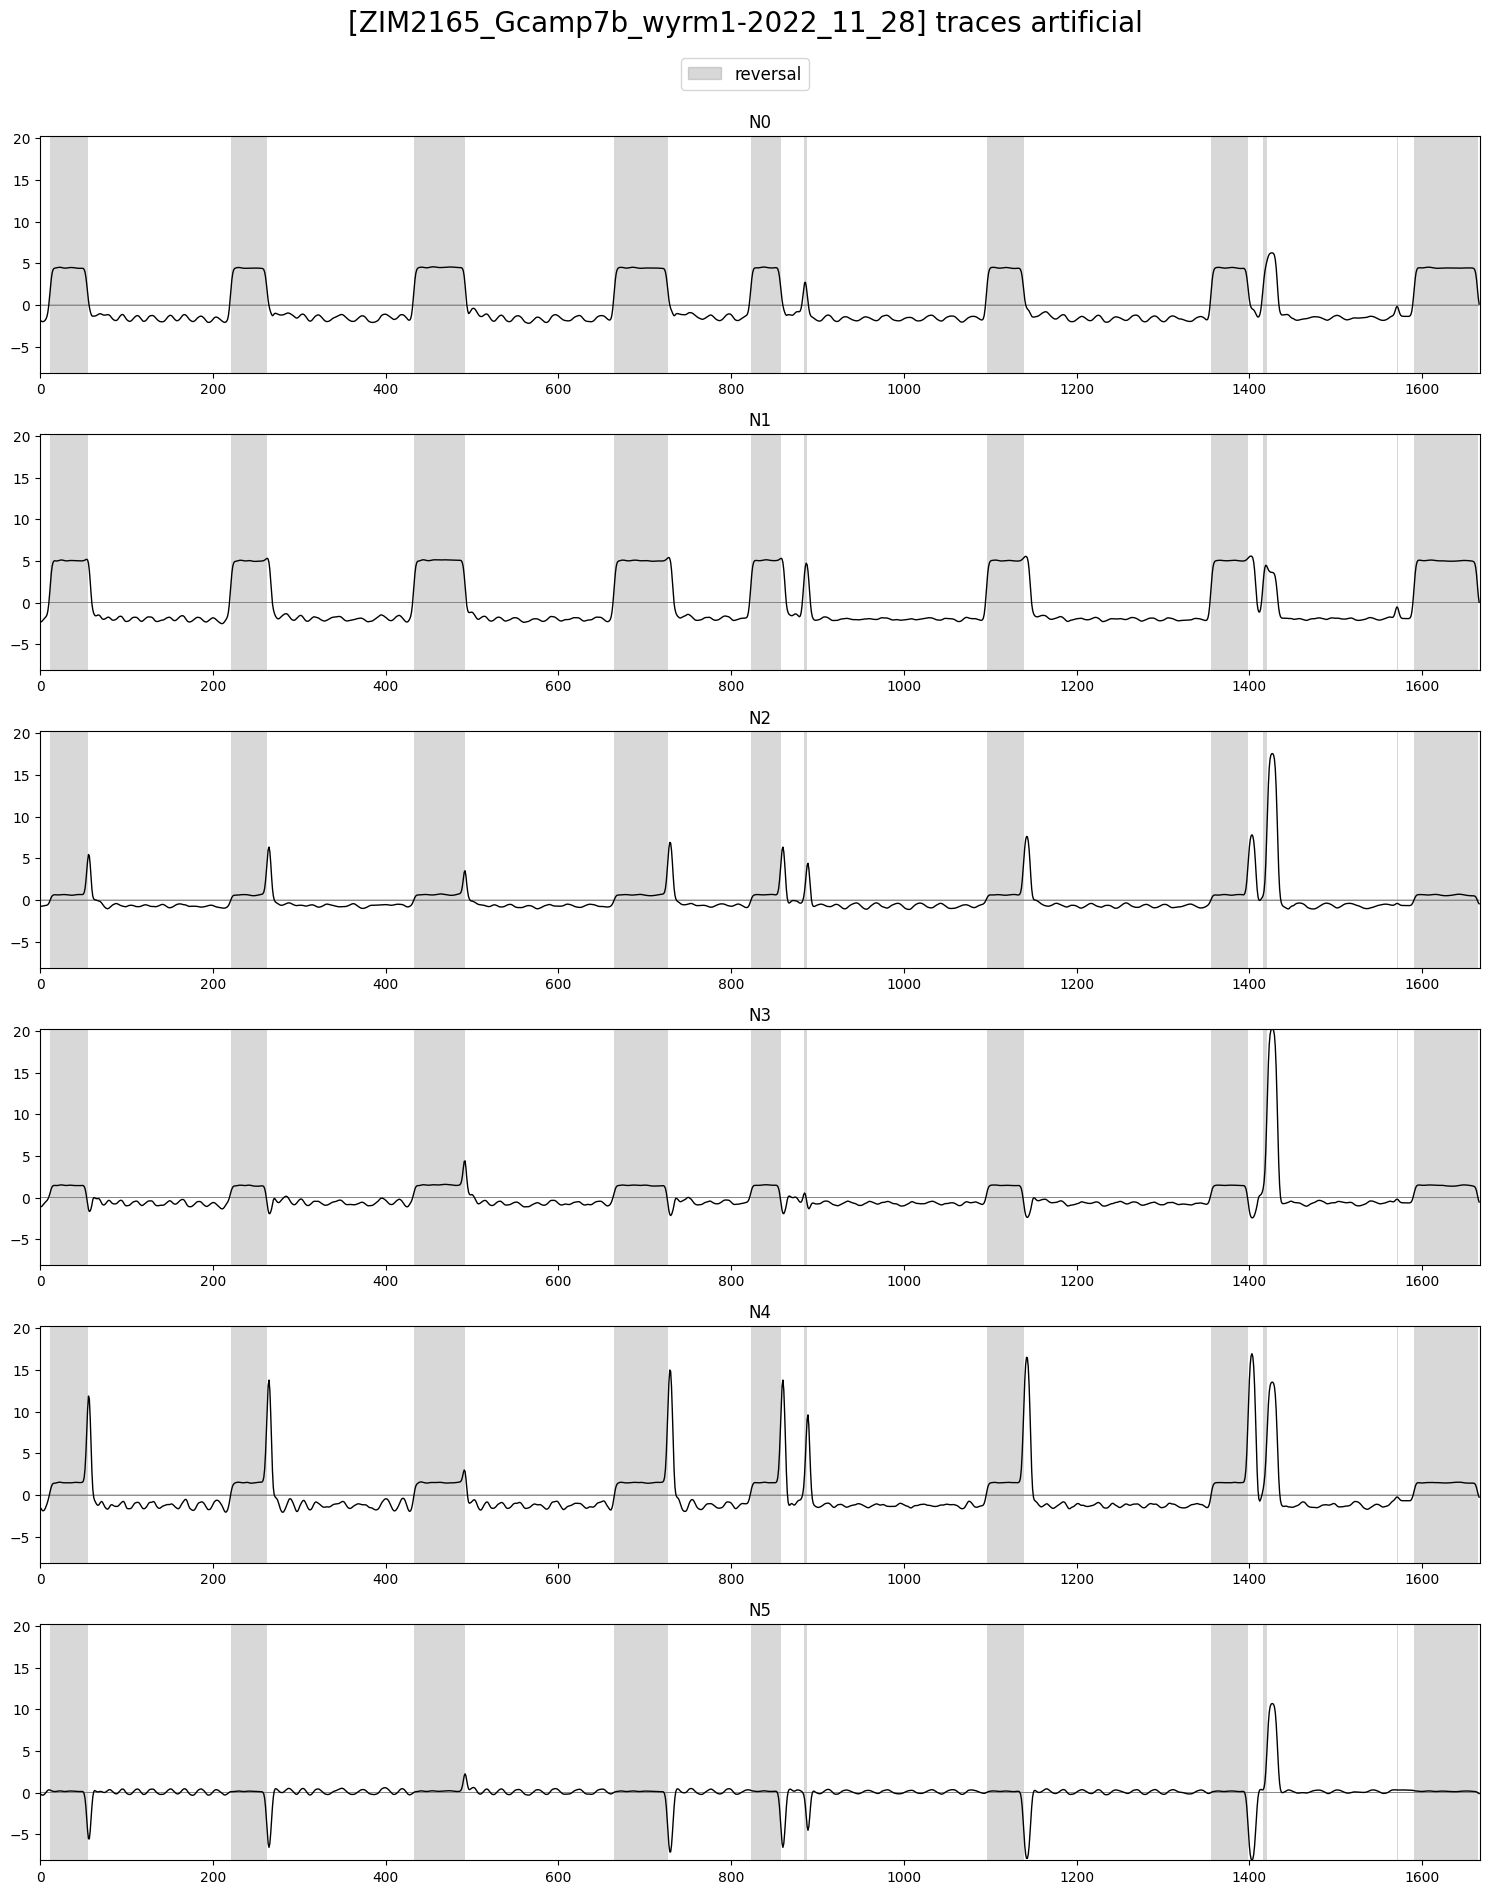

In [12]:
plot_utils.plot_traces(traces[neurons],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces artificial', ylimits=None, plots_per_row=1)